In [2]:
from loader import DSMCDataProcessor
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


In [3]:
data_processor = DSMCDataProcessor("/media/astrojose/AstroBook/ArchiveSims/Results_20250219_040340.877")
data_processor.load_data()
data_processor.load_parameters()

Loading surface and escape data...
Surface and escape data loaded successfully.

Surface Data Structure:
Base properties: ['time', 'avg_time_interval', 'rad', 'zen', 'azi', 'cell_num', 'lower_area']
Species properties: ['num_part_inject', 'num_part_return', 'num_part_reemit', 'num_part_surf', 'inject_rate', 'return_rate', 'reemit_rate', 'return_time', 'inject_energy', 'return_energy']
Number of species: 1

Escape Data Structure:
Base properties: ['time', 'avg_time_interval', 'rad', 'zen', 'azi', 'cell_num', 'upper_area']
Species properties: ['num_part_escape', 'num_part_ball', 'escape_rate', 'escape_time', 'escape_speed', 'escape_energy']
Number of species: 1
NpzFile '/media/astrojose/AstroBook/ArchiveSims/Results_20250219_040340.877/params_data.npz' with keys: time, timestep, radial_cells, mars_radius, wave_action


In [4]:
data_processor.get_surface_property("num_part_inject", 0)

array([1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000., 1000.,
       1000.])

Text(0, 0.5, 'Escape Rate (1/s)')

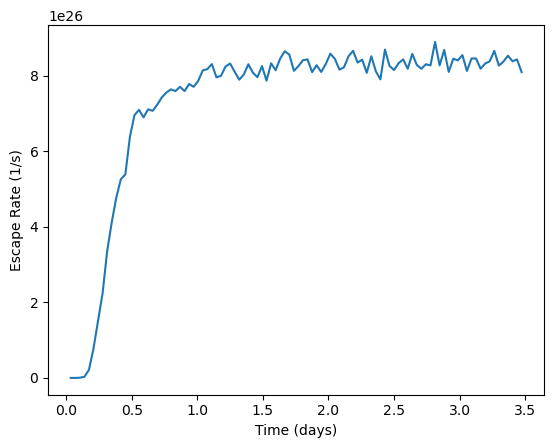

In [5]:
plt.plot(data_processor.params.time / 3600 / 24, data_processor.get_escape_property('escape_rate', 0))
plt.xlabel('Time (days)')
plt.ylabel('Escape Rate (1/s)')

In [6]:
data_processor.temperature_data.shape

(100, 128, 1)

In [7]:
data_processor.params.time

array([  3000.,   6000.,   9000.,  12000.,  15000.,  18000.,  21000.,
        24000.,  27000.,  30000.,  33000.,  36000.,  39000.,  42000.,
        45000.,  48000.,  51000.,  54000.,  57000.,  60000.,  63000.,
        66000.,  69000.,  72000.,  75000.,  78000.,  81000.,  84000.,
        87000.,  90000.,  93000.,  96000.,  99000., 102000., 105000.,
       108000., 111000., 114000., 117000., 120000., 123000., 126000.,
       129000., 132000., 135000., 138000., 141000., 144000., 147000.,
       150000., 153000., 156000., 159000., 162000., 165000., 168000.,
       171000., 174000., 177000., 180000., 183000., 186000., 189000.,
       192000., 195000., 198000., 201000., 204000., 207000., 210000.,
       213000., 216000., 219000., 222000., 225000., 228000., 231000.,
       234000., 237000., 240000., 243000., 246000., 249000., 252000.,
       255000., 258000., 261000., 264000., 267000., 270000., 273000.,
       276000., 279000., 282000., 285000., 288000., 291000., 294000.,
       297000., 3000

In [8]:
data_processor.params.radial_cells[-3]

np.float64(39429.92531775674)

Altitude: 12,500 km


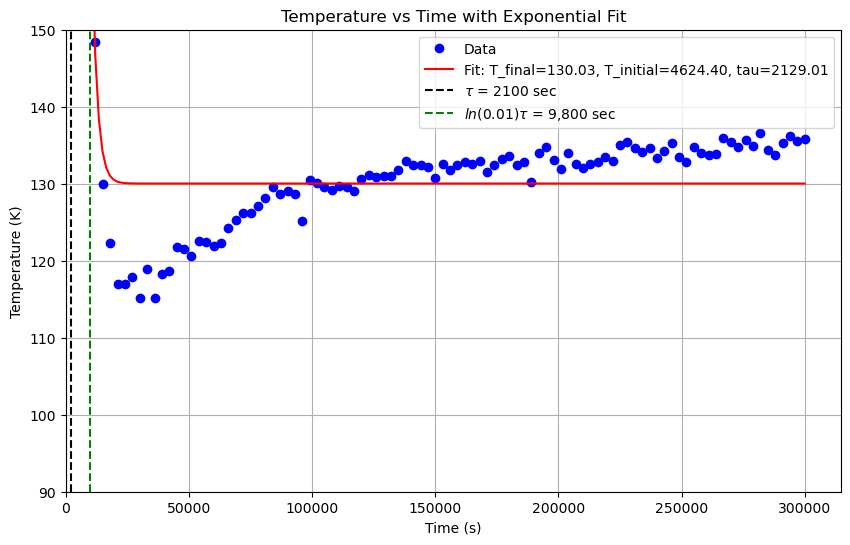

In [25]:
alt_idx = 40
print(f"Altitude: {round(data_processor.params.radial_cells[alt_idx], -2):,.0f} km")

temperature_value = data_processor.temperature_data[:, alt_idx]

# Flatten the temperature_value array if needed
t = data_processor.params.time
T = temperature_value.flatten()

# Filter out temperature points above 1000 K
mask = T <= 1200
mask2 = t >= 5e3

t_filtered = t[mask & mask2]
T_filtered = T[mask & mask2]

def exp_func(t, T_final, T_initial, tau):
    return T_final + (T_initial - T_final) * np.exp(-t / tau)

# Provide initial guesses for the parameters using filtered data
popt, pcov = curve_fit(exp_func, t_filtered, T_filtered, p0=(20, 300, 10000))

t_fit = np.linspace(t_filtered.min(), t_filtered.max(), 200)
T_fit = exp_func(t_fit, *popt)

plt.figure(figsize=(10, 6))
plt.plot(t_filtered, T_filtered, 'bo', label='Data')
plt.plot(t_fit, T_fit, 'r-', label=f'Fit: T_final={popt[0]:.2f}, T_initial={popt[1]:.2f}, tau={popt[2]:.2f}')
plt.axvline(popt[2], color='k', linestyle='--', label=f'$\\tau$ = {round(popt[2], -2):.0f} sec')
plt.axvline(4.61 * popt[2], color='g', linestyle='--', label=f'$ln(0.01)\\tau$ = {round(np.log(0.01) * - popt[2], -2):,.0f} sec')
plt.ylim(*np.percentile(T_filtered, [1, 100]))
plt.xlim(left=0)
plt.xlabel("Time (s)")
plt.ylabel("Temperature (K)")
plt.title("Temperature vs Time with Exponential Fit")
plt.ylim(90, 150)
plt.legend()
plt.grid(True)
plt.show()

In [26]:
def thermal_response_model(t, T_final, T_initial, tau1, A_under, t0, sigma, A_osc, tau2, omega, phi):
    cooling = T_final + (T_initial - T_final) * np.exp(-t/tau1)
    undercooling = A_under * np.exp(-(t-t0)**2/(2*sigma**2))
    oscillation = A_osc * np.exp(-t/tau2) * np.sin(omega*t + phi)
    return cooling + undercooling + oscillation

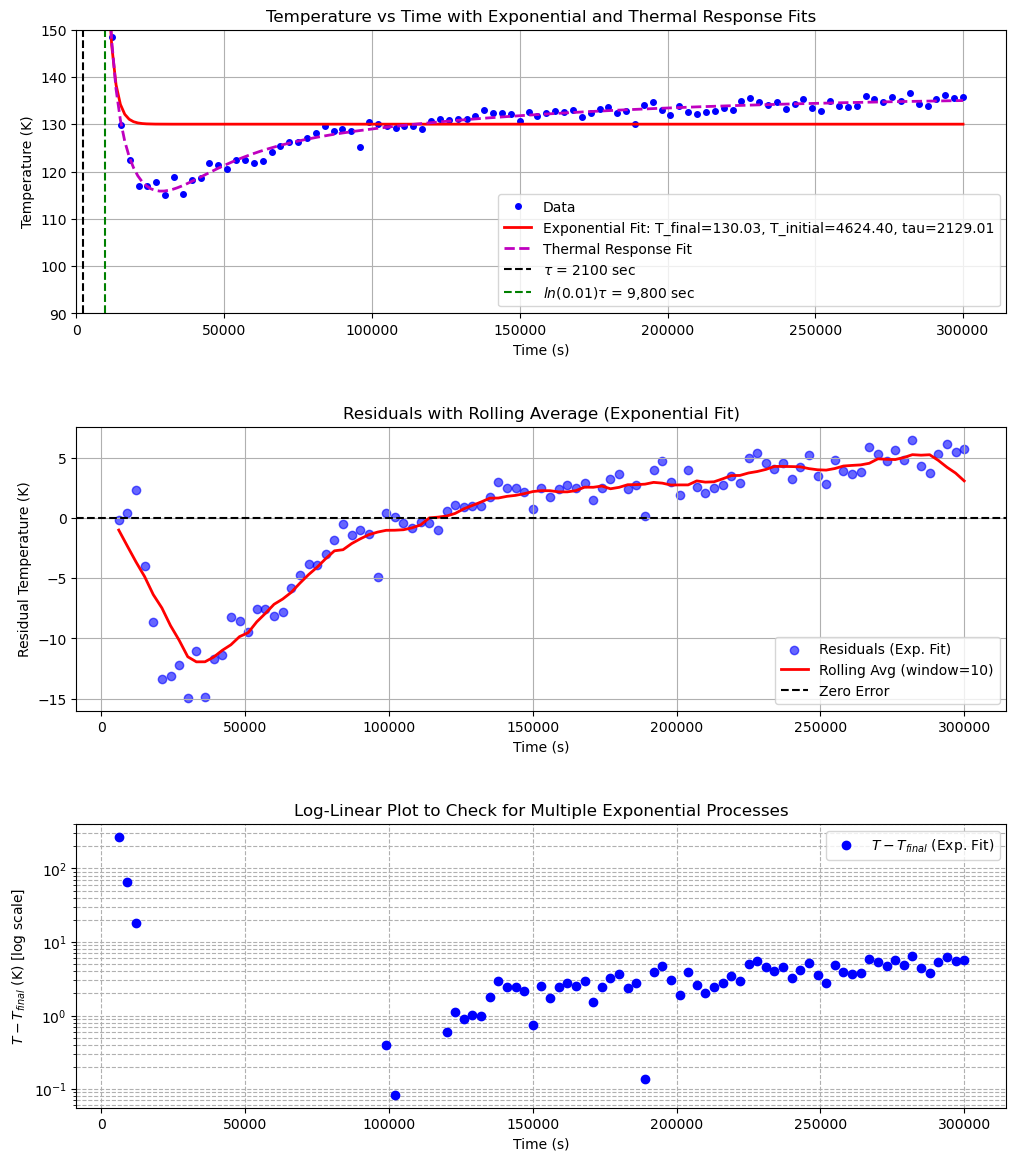

In [28]:
import matplotlib.gridspec as gridspec

# --- Fit 1: Simple Exponential Model ---
popt_exp, pcov_exp = curve_fit(exp_func, t_filtered, T_filtered, p0=(20, 300, 10000))
t_fit = np.linspace(t_filtered.min(), t_filtered.max(), 200)
T_fit_exp = exp_func(t_fit, *popt_exp)

# --- Fit 2: Thermal Response Model ---
p0_thermal = [
    113,      # T_final
    3900,     # T_initial
    3000,     # tau1
    -7,       # A_under
    50000,    # t0
    15000,    # sigma
    2,        # A_osc
    100000,   # tau2
    2*np.pi/100000,  # omega
    np.pi/2   # phi
]
popt_thermal, pcov_thermal = curve_fit(
    thermal_response_model, t_filtered, T_filtered, p0=p0_thermal, maxfev=100000
)
T_fit_thermal = thermal_response_model(t_fit, *popt_thermal)

# --- Compute residuals and rolling average for the exponential fit ---
residuals = T_filtered - exp_func(t_filtered, *popt_exp)
window_size = 10
rolling_avg = np.convolve(residuals, np.ones(window_size)/window_size, mode='same')

# --- Compute log-linear data for the exponential fit ---
T_final_exp = popt_exp[0]
excess_T = T_filtered - T_final_exp
mask_log = excess_T > 0

# --- Create gridspec layout ---
fig = plt.figure(figsize=(12, 14))
gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1], hspace=0.4)

# Subplot 1: Temperature vs Time with Both Fits
ax1 = fig.add_subplot(gs[0])
ax1.plot(t_filtered, T_filtered, 'bo', markersize=4, label='Data')
ax1.plot(t_fit, T_fit_exp, 'r-', linewidth=2, label=f'Exponential Fit: T_final={popt_exp[0]:.2f}, T_initial={popt_exp[1]:.2f}, tau={popt_exp[2]:.2f}')
ax1.plot(t_fit, T_fit_thermal, 'm--', linewidth=2, label='Thermal Response Fit')
# Vertical lines indicating characteristic times for the exponential fit
ax1.axvline(popt_exp[2], color='k', linestyle='--', label=f'$\\tau$ = {round(popt_exp[2], -2):.0f} sec')
ax1.axvline(4.61 * popt_exp[2], color='g', linestyle='--', label=f'$ln(0.01)\\tau$ = {round(4.61 * popt_exp[2], -2):,.0f} sec')
ax1.set_xlim(left=0)
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Temperature (K)")
ax1.set_title("Temperature vs Time with Exponential and Thermal Response Fits")
ax1.set_ylim(90, 150)
ax1.legend()
ax1.grid(True)

# Subplot 2: Residuals (Exponential Fit) with Rolling Average
ax2 = fig.add_subplot(gs[1])
ax2.scatter(t_filtered, residuals, color='blue', alpha=0.6, label='Residuals (Exp. Fit)')
ax2.plot(t_filtered, rolling_avg, color='red', linewidth=2, label=f'Rolling Avg (window={window_size})')
ax2.axhline(0, color='black', linestyle='--', label='Zero Error')
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Residual Temperature (K)")
ax2.set_title("Residuals with Rolling Average (Exponential Fit)")
ax2.legend()
ax2.grid(True)

# Subplot 3: Log-Linear Plot (Exponential Fit)
ax3 = fig.add_subplot(gs[2])
ax3.semilogy(t_filtered[mask_log], excess_T[mask_log], 'bo', label='$T-T_{final}$ (Exp. Fit)')
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("$T-T_{final}$ (K) [log scale]")
ax3.set_title("Log-Linear Plot to Check for Multiple Exponential Processes")
ax3.legend()
ax3.grid(True, which='both', linestyle='--')

plt.show()

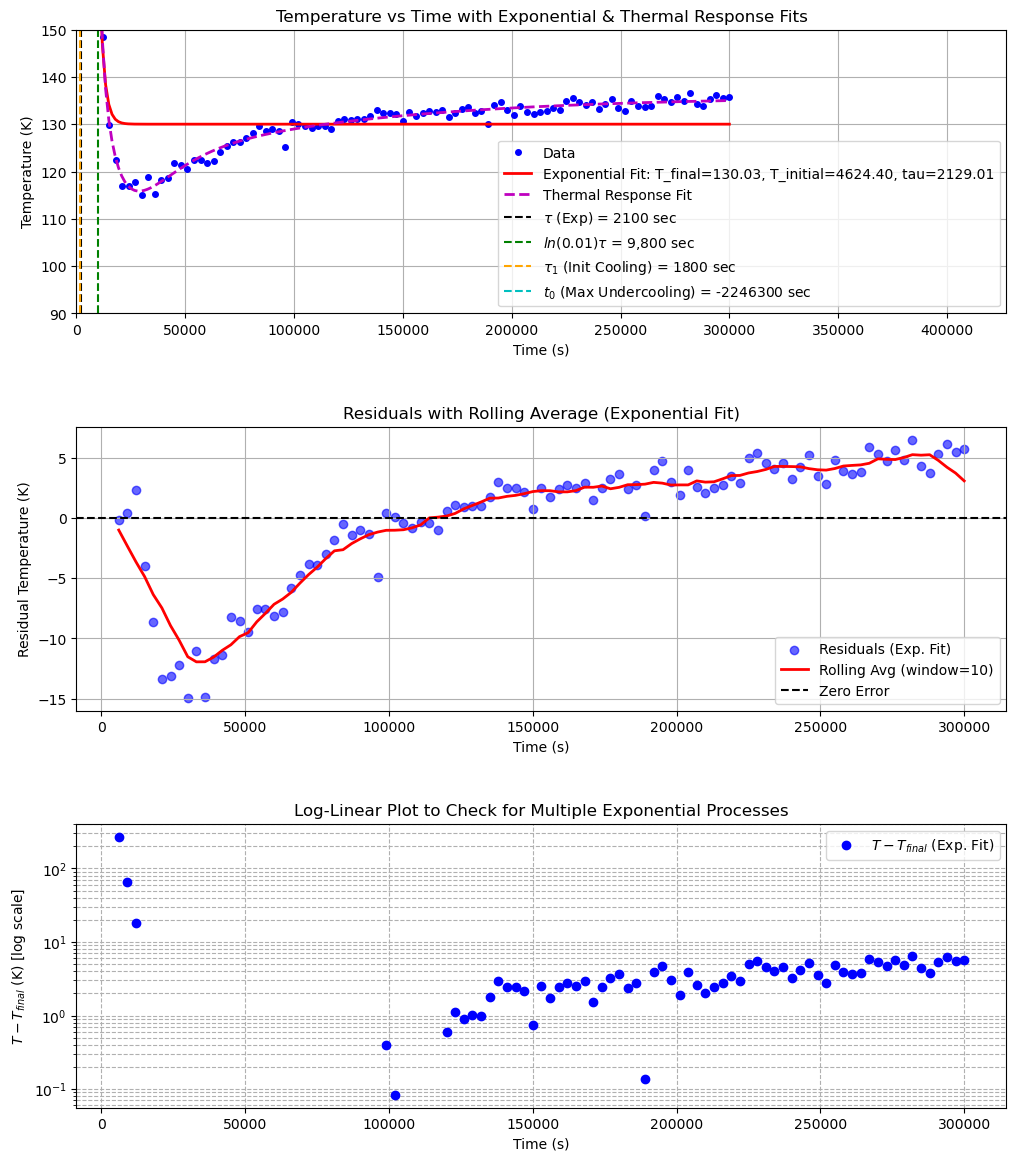

In [29]:
import matplotlib.gridspec as gridspec

# --- Fit 1: Simple Exponential Model ---
popt_exp, pcov_exp = curve_fit(exp_func, t_filtered, T_filtered, p0=(20, 300, 10000))
t_fit = np.linspace(t_filtered.min(), t_filtered.max(), 200)
T_fit_exp = exp_func(t_fit, *popt_exp)

# --- Fit 2: Thermal Response Model ---
p0_thermal = [
    113,      # T_final
    3900,     # T_initial
    3000,     # tau1 (initial cooling)
    -7,       # A_under
    50000,    # t0 (time of maximum undercooling)
    15000,    # sigma
    2,        # A_osc
    100000,   # tau2
    2*np.pi/100000,  # omega
    np.pi/2   # phi
]
popt_thermal, pcov_thermal = curve_fit(
    thermal_response_model, t_filtered, T_filtered, p0=p0_thermal, maxfev=100000
)
T_fit_thermal = thermal_response_model(t_fit, *popt_thermal)

# --- Compute residuals and rolling average for the exponential fit ---
residuals = T_filtered - exp_func(t_filtered, *popt_exp)
window_size = 10
rolling_avg = np.convolve(residuals, np.ones(window_size)/window_size, mode='same')

# --- Compute log-linear data for the exponential fit ---
T_final_exp = popt_exp[0]
excess_T = T_filtered - T_final_exp
mask_log = excess_T > 0

# --- Create gridspec layout ---
fig = plt.figure(figsize=(12, 14))
gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1], hspace=0.4)

# Subplot 1: Temperature vs Time with Both Fits and Characteristic Times
ax1 = fig.add_subplot(gs[0])
ax1.plot(t_filtered, T_filtered, 'bo', markersize=4, label='Data')
ax1.plot(t_fit, T_fit_exp, 'r-', linewidth=2, label=f'Exponential Fit: T_final={popt_exp[0]:.2f}, T_initial={popt_exp[1]:.2f}, tau={popt_exp[2]:.2f}')
ax1.plot(t_fit, T_fit_thermal, 'm--', linewidth=2, label='Thermal Response Fit')
# Vertical lines for exponential fit characteristic times
ax1.axvline(popt_exp[2], color='k', linestyle='--', label=f'$\\tau$ (Exp) = {round(popt_exp[2], -2):.0f} sec')
ax1.axvline(4.61 * popt_exp[2], color='g', linestyle='--', label=f'$ln(0.01)\\tau$ = {round(4.61 * popt_exp[2], -2):,.0f} sec')
# Vertical lines for thermal response model characteristic times:
ax1.axvline(popt_thermal[2], color='orange', linestyle='--', label=f'$\\tau_1$ (Init Cooling) = {round(popt_thermal[2], -2):.0f} sec')
ax1.axvline(popt_thermal[4], color='c', linestyle='--', label=f'$t_0$ (Max Undercooling) = {round(popt_thermal[4], -2):.0f} sec')
ax1.set_xlim(left=0)
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Temperature (K)")
ax1.set_title("Temperature vs Time with Exponential & Thermal Response Fits")
ax1.set_ylim(90, 150)
ax1.legend()
ax1.grid(True)

# Subplot 2: Residuals (Exponential Fit) with Rolling Average
ax2 = fig.add_subplot(gs[1])
ax2.scatter(t_filtered, residuals, color='blue', alpha=0.6, label='Residuals (Exp. Fit)')
ax2.plot(t_filtered, rolling_avg, color='red', linewidth=2, label=f'Rolling Avg (window={window_size})')
ax2.axhline(0, color='black', linestyle='--', label='Zero Error')
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Residual Temperature (K)")
ax2.set_title("Residuals with Rolling Average (Exponential Fit)")
ax2.legend()
ax2.grid(True)

# Subplot 3: Log-Linear Plot (Exponential Fit)
ax3 = fig.add_subplot(gs[2])
ax3.semilogy(t_filtered[mask_log], excess_T[mask_log], 'bo', label='$T-T_{final}$ (Exp. Fit)')
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("$T-T_{final}$ (K) [log scale]")
ax3.set_title("Log-Linear Plot to Check for Multiple Exponential Processes")
ax3.legend()
ax3.grid(True, which='both', linestyle='--')

plt.show()

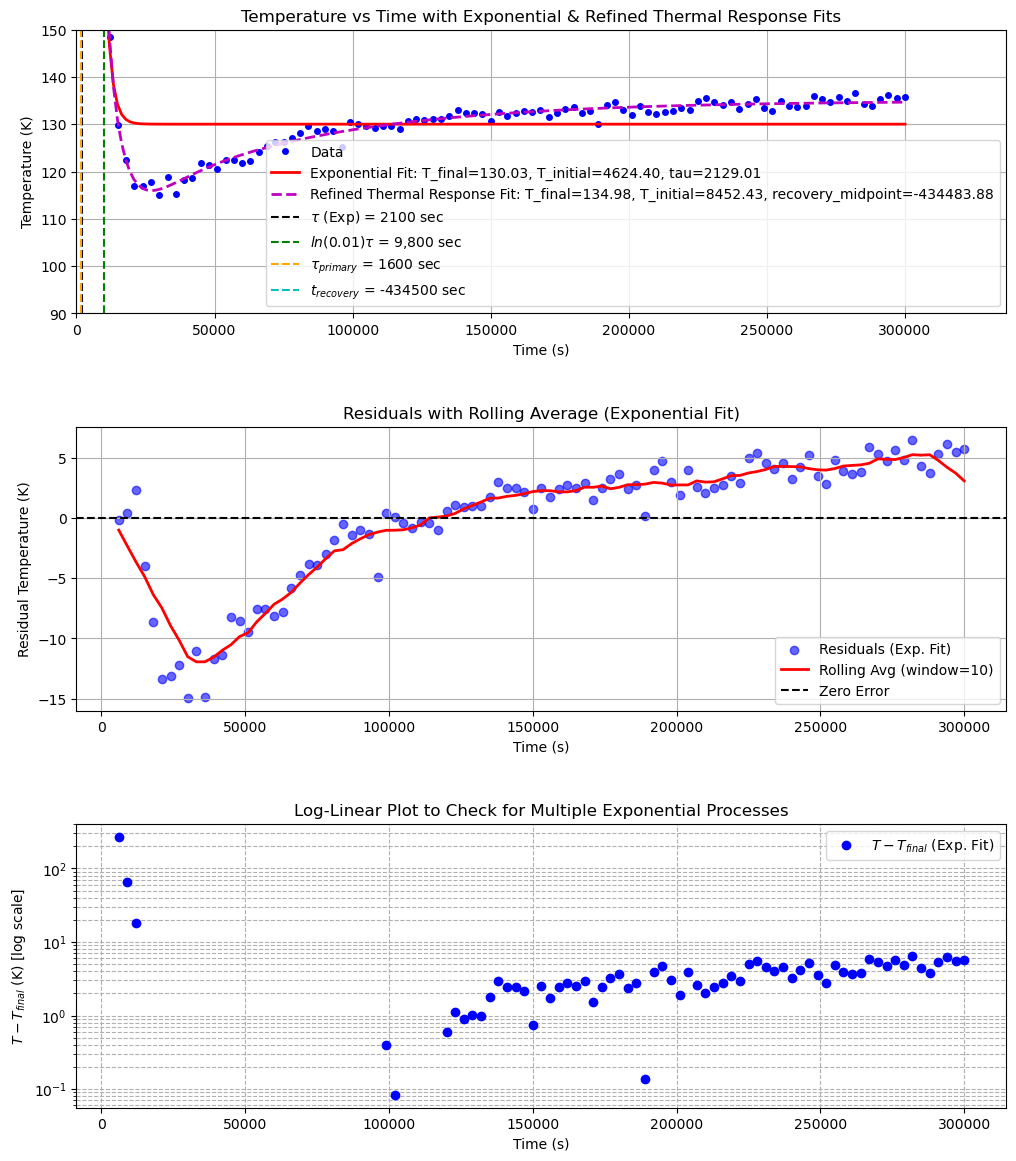

In [32]:
def refined_thermal_model(t, T_final, T_initial, tau_primary, recovery_amplitude,
                          recovery_midpoint, recovery_rate, oscillation_amplitude,
                          oscillation_period, oscillation_phase):
    # Primary cooling component
    cooling_term = (T_initial - T_final) * np.exp(-t/tau_primary)

    # Recovery function using logistic formulation
    recovery_term = recovery_amplitude * (1 / (1 + np.exp(-(t - recovery_midpoint)/recovery_rate)))

    # Oscillatory component with proper damping
    oscillation_term = oscillation_amplitude * np.exp(-t/(5*tau_primary)) * \
                       np.sin(2*np.pi*t/oscillation_period + oscillation_phase)

    return T_final + cooling_term - recovery_amplitude + recovery_term + oscillation_term

# --- Fit the refined thermal model ---
p0_refined = [
    130.0,    # T_final - final equilibrium temperature
    4600.0,   # T_initial - initial temperature
    2100.0,   # tau_primary - primary cooling timescale
    10.0,     # recovery_amplitude - magnitude of undercooling
    50000.0,  # recovery_midpoint - center of recovery phase
    10000.0,  # recovery_rate - rapidity of recovery transition
    2.0,      # oscillation_amplitude - magnitude of oscillations
    80000.0,  # oscillation_period - period of oscillatory behavior
    np.pi/2   # oscillation_phase - phase offset for oscillations
]
popt_refined, pcov_refined = curve_fit(refined_thermal_model, t_filtered, T_filtered, p0=p0_refined, maxfev=100000)
T_fit_refined = refined_thermal_model(t_fit, *popt_refined)

# --- Compute residuals and rolling average for the exponential fit ---
residuals = T_filtered - exp_func(t_filtered, *popt_exp)
window_size = 10
rolling_avg = np.convolve(residuals, np.ones(window_size)/window_size, mode='same')

# --- Compute log-linear data for the exponential fit ---
T_final_exp = popt_exp[0]
excess_T = T_filtered - T_final_exp
mask_log = excess_T > 0

# --- Create gridspec layout for 3 subplots ---
fig = plt.figure(figsize=(12, 14))
gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1], hspace=0.4)

# Subplot 1: Temperature vs Time with Exponential & Refined Thermal Response Fits
ax1 = fig.add_subplot(gs[0])
ax1.plot(t_filtered, T_filtered, 'bo', markersize=4, label='Data')
ax1.plot(t_fit, T_fit_exp, 'r-', linewidth=2,
         label=f'Exponential Fit: T_final={popt_exp[0]:.2f}, T_initial={popt_exp[1]:.2f}, tau={popt_exp[2]:.2f}')
ax1.plot(t_fit, T_fit_refined, 'm--', linewidth=2, label=f'Refined Thermal Response Fit: T_final={popt_refined[0]:.2f}, T_initial={popt_refined[1]:.2f}, recovery_midpoint={popt_refined[4]:.2f}')
# Vertical lines for exponential fit characteristic times
ax1.axvline(popt_exp[2], color='k', linestyle='--',
            label=f'$\\tau$ (Exp) = {round(popt_exp[2], -2):.0f} sec')
ax1.axvline(4.61 * popt_exp[2], color='g', linestyle='--',
            label=f'$ln(0.01)\\tau$ = {round(4.61 * popt_exp[2], -2):,.0f} sec')
# Vertical lines for refined model characteristic times:
ax1.axvline(popt_refined[2], color='orange', linestyle='--',
            label=f'$\\tau_{{primary}}$ = {round(popt_refined[2], -2):.0f} sec')
ax1.axvline(popt_refined[4], color='c', linestyle='--',
            label=f'$t_{{recovery}}$ = {round(popt_refined[4], -2):.0f} sec')
ax1.set_xlim(left=0)
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Temperature (K)")
ax1.set_title("Temperature vs Time with Exponential & Refined Thermal Response Fits")
ax1.set_ylim(90, 150)
ax1.legend()
ax1.grid(True)

# Subplot 2: Residuals (Exponential Fit) with Rolling Average
ax2 = fig.add_subplot(gs[1])
ax2.scatter(t_filtered, residuals, color='blue', alpha=0.6, label='Residuals (Exp. Fit)')
ax2.plot(t_filtered, rolling_avg, color='red', linewidth=2,
         label=f'Rolling Avg (window={window_size})')
ax2.axhline(0, color='black', linestyle='--', label='Zero Error')
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Residual Temperature (K)")
ax2.set_title("Residuals with Rolling Average (Exponential Fit)")
ax2.legend()
ax2.grid(True)

# Subplot 3: Log-Linear Plot (Exponential Fit)
ax3 = fig.add_subplot(gs[2])
ax3.semilogy(t_filtered[mask_log], excess_T[mask_log], 'bo', label='$T-T_{final}$ (Exp. Fit)')
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("$T-T_{final}$ (K) [log scale]")
ax3.set_title("Log-Linear Plot to Check for Multiple Exponential Processes")
ax3.legend()
ax3.grid(True, which='both', linestyle='--')

plt.show()

In [37]:
popt_refined[2]

np.float64(1590.5333363589448)

In [46]:
RRF

array([3.16539733e-02, 7.33670100e-03, 1.61546531e-03, 6.08365764e-04,
       1.51668913e-03, 2.17079256e-03, 2.16829661e-03, 2.06102063e-03,
       2.38949163e-03, 1.92838347e-03, 2.37850495e-03, 2.00642692e-03,
       1.96282194e-03, 1.58723799e-03, 1.62408661e-03, 1.73215952e-03,
       1.49988650e-03, 1.50735647e-03, 1.57687782e-03, 1.53193933e-03,
       1.29615693e-03, 1.16175771e-03, 1.05816593e-03, 1.06201338e-03,
       9.52055632e-04, 8.17054233e-04, 6.51143972e-04, 7.61476608e-04,
       7.15709489e-04, 7.59330345e-04, 1.18507242e-03, 5.47602827e-04,
       5.85753104e-04, 6.45977236e-04, 6.96642438e-04, 6.37508202e-04,
       6.43207292e-04, 7.13100859e-04, 5.24663589e-04, 4.63379090e-04,
       4.87128454e-04, 4.74354207e-04, 4.75994994e-04, 3.81456554e-04,
       2.39089351e-04, 2.99193752e-04, 2.99945941e-04, 3.34842597e-04,
       5.07275876e-04, 2.95086513e-04, 3.89075599e-04, 3.06564045e-04,
       2.64275589e-04, 2.91846091e-04, 2.44055903e-04, 4.14916913e-04,
      

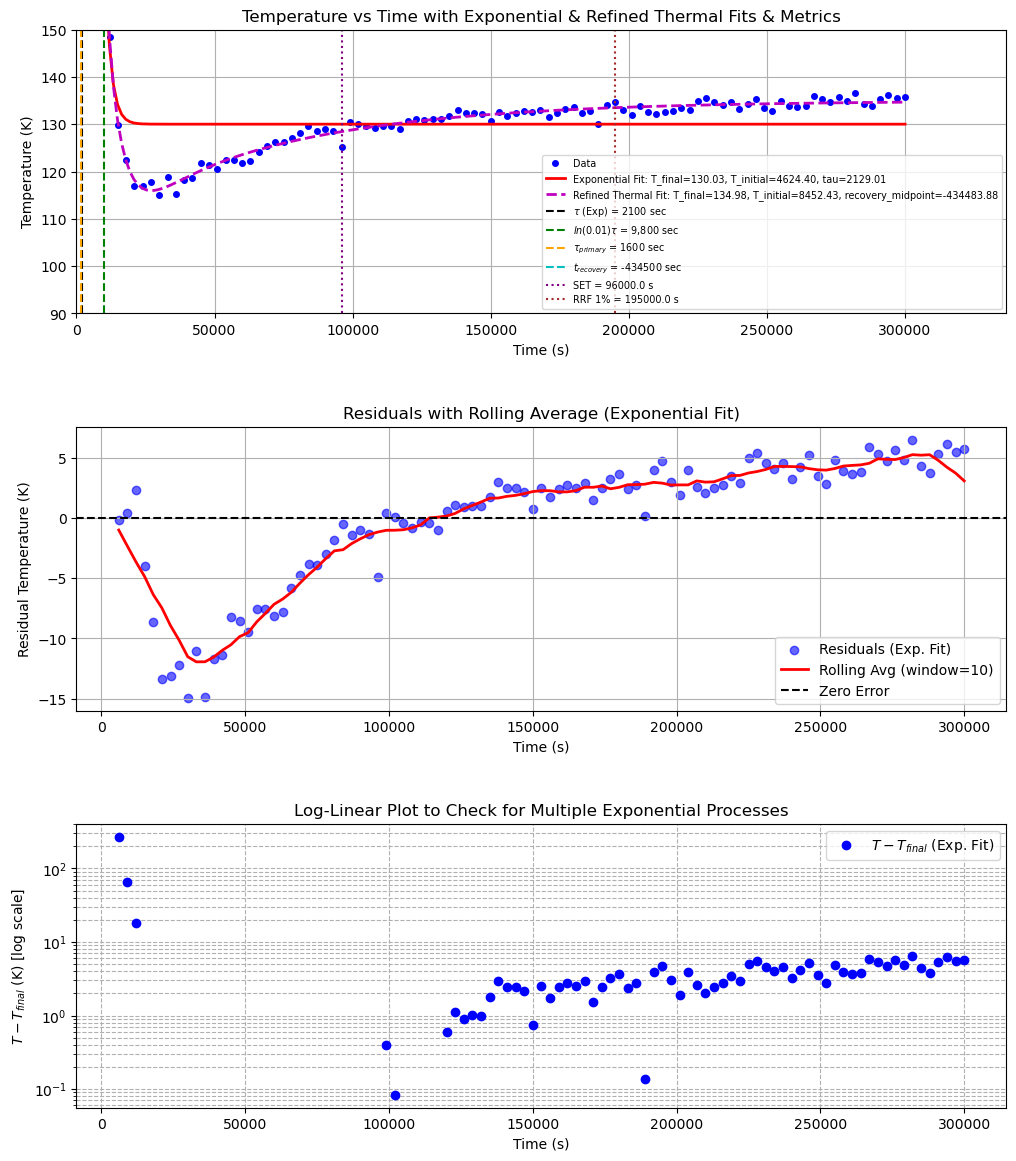

In [49]:
# --- Compute SET (Statistical Equilibration Time) from the data ---
epsilon = 2  # threshold in K for standard deviation
times_sorted = np.sort(t_filtered)
SET = None
for t_val in times_sorted:
    if np.std(T_filtered[t_filtered > t_val]) < epsilon:
        SET = t_val
        break
if SET is None:
    SET = 130000  # use estimated value if not found

# --- Compute RRF (Residual Relaxation Function) and t_RRF (1% threshold) ---
# RRF for the refined fit using popt_refined: T_final and T_initial from the refined fit.
RRF = np.abs(T_filtered - popt_refined[0]) / (popt_refined[1] - popt_refined[0])
t_RRF_candidates = t_filtered[(RRF < 0.0001)]  # threshold 1%
if len(t_RRF_candidates) > 0:
    t_RRF = t_RRF_candidates.min()
else:
    t_RRF = 100000  # fallback estimate

# --- Create gridspec layout (3 subplots) ---
fig = plt.figure(figsize=(12, 14))
gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1], hspace=0.4)

# Subplot 1: Temperature vs Time with Exponential & Refined Thermal Response Fits and Metrics
ax1 = fig.add_subplot(gs[0])
ax1.plot(t_filtered, T_filtered, 'bo', markersize=4, label='Data')
ax1.plot(t_fit, T_fit_exp, 'r-', linewidth=2,
         label=f'Exponential Fit: T_final={popt_exp[0]:.2f}, T_initial={popt_exp[1]:.2f}, tau={popt_exp[2]:.2f}')
ax1.plot(t_fit, T_fit_refined, 'm--', linewidth=2,
         label=f'Refined Thermal Fit: T_final={popt_refined[0]:.2f}, T_initial={popt_refined[1]:.2f}, recovery_midpoint={popt_refined[4]:.2f}')
# Vertical lines for exponential fit characteristic times
ax1.axvline(popt_exp[2], color='k', linestyle='--',
            label=f'$\\tau$ (Exp) = {round(popt_exp[2], -2):.0f} sec')
ax1.axvline(4.61 * popt_exp[2], color='g', linestyle='--',
            label=f'$ln(0.01)\\tau$ = {round(4.61 * popt_exp[2], -2):,.0f} sec')
# Vertical lines for refined model characteristic times:
ax1.axvline(popt_refined[2], color='orange', linestyle='--',
            label=f'$\\tau_{{primary}}$ = {round(popt_refined[2], -2):.0f} sec')
ax1.axvline(popt_refined[4], color='c', linestyle='--',
            label=f'$t_{{recovery}}$ = {round(popt_refined[4], -2):.0f} sec')
# Vertical lines for the new metrics:
ax1.axvline(SET, color='purple', linestyle=':', label=f'SET = {round(SET,0)} s')
ax1.axvline(t_RRF, color='brown', linestyle=':', label=f'RRF 1% = {round(t_RRF,0)} s')
ax1.set_xlim(left=0)
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Temperature (K)")
ax1.set_title("Temperature vs Time with Exponential & Refined Thermal Fits & Metrics")
ax1.set_ylim(90, 150)
ax1.legend(fontsize='x-small')
ax1.grid(True)

# Subplot 2: Residuals (Exponential Fit) with Rolling Average
ax2 = fig.add_subplot(gs[1])
ax2.scatter(t_filtered, residuals, color='blue', alpha=0.6, label='Residuals (Exp. Fit)')
ax2.plot(t_filtered, rolling_avg, color='red', linewidth=2,
         label=f'Rolling Avg (window={window_size})')
ax2.axhline(0, color='black', linestyle='--', label='Zero Error')
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Residual Temperature (K)")
ax2.set_title("Residuals with Rolling Average (Exponential Fit)")
ax2.legend()
ax2.grid(True)

# Subplot 3: Log-Linear Plot (Exponential Fit)
ax3 = fig.add_subplot(gs[2])
ax3.semilogy(t_filtered[mask_log], excess_T[mask_log], 'bo', label='$T-T_{final}$ (Exp. Fit)')
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("$T-T_{final}$ (K) [log scale]")
ax3.set_title("Log-Linear Plot to Check for Multiple Exponential Processes")
ax3.legend()
ax3.grid(True, which='both', linestyle='--')

plt.show()

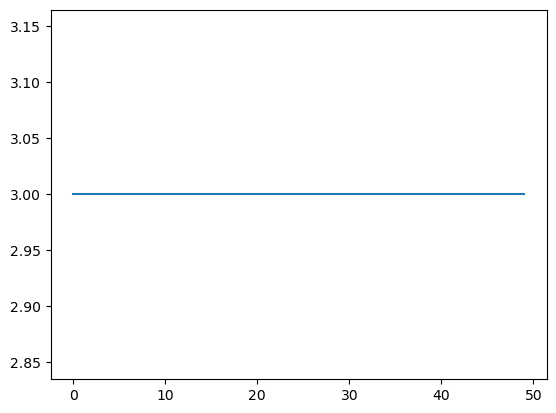

In [11]:
data_processor.knudsen_data.shape # (100, 128, 1)

# Identify the position where kn = 1 along the second axis, for the second half of the simulation (50-100)
kn_values = data_processor.knudsen_data[50:, :, 0]

# Find the index of the first occurrence of kn = 1
index = np.argmax(kn_values >= 1, axis=1)

# Plot the index values
plt.plot(index)

In [12]:
kn_values[10, 4]

np.float64(2.4261563522945067)